In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [2]:
from pathlib import Path

DATA_DIR = next(
    (path for path in (Path('data/raw'), Path('../data/raw')) if path.is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(f'Could not find data/raw from {Path.cwd()}')

sales = pd.read_csv(DATA_DIR / 'sales_train_evaluation.csv')
calendar = pd.read_csv(DATA_DIR / 'calendar.csv')
sell_prices = pd.read_csv(DATA_DIR / 'sell_prices.csv')

In [3]:
print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)
print("Sell prices shape:", sell_prices.shape)

Sales shape: (30490, 1947)
Calendar shape: (1969, 14)
Sell prices shape: (6841121, 4)


In [4]:
print("\nSales:")
print(sales.head())

print("\nCalendar:")
print(calendar.head())  

print("\nSell prices:")
print(sell_prices.head())


Sales:
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  d_5  d_6  d_7  d_8  d_9  d_10  d_11  d_12  \
0       CA    0    0    0    0    0    0    0    0    0     0     0     0   
1       CA    0    0    0    0    0    0    0    0    0     0     0     0   
2       CA    0    0    0    0    0    0    0    0    0     0     0     0   
3       CA    0    0    0    0    0    0    0    0    0     0     0     0   
4       CA    0    0    0    0    0    0    0    0    0     0     0     0   

   d_13  d_14  d_15  d_16  d_17  d_18  d_19  d_2

         Understand sales dataset


In [5]:
print("Columns:")
print(sales.columns.tolist())

print("\nData types:")
print(sales.dtypes)

print("\nMissing values:")
print(sales.isnull().sum().sum())

print("\nUnique values:")
print("Items:", sales['item_id'].nunique())
print("Departments:", sales['dept_id'].nunique())
print("Categories:", sales['cat_id'].nunique())
print("Stores:", sales['store_id'].nunique())
print("States:", sales['state_id'].nunique())

Columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9', 'd_10', 'd_11', 'd_12', 'd_13', 'd_14', 'd_15', 'd_16', 'd_17', 'd_18', 'd_19', 'd_20', 'd_21', 'd_22', 'd_23', 'd_24', 'd_25', 'd_26', 'd_27', 'd_28', 'd_29', 'd_30', 'd_31', 'd_32', 'd_33', 'd_34', 'd_35', 'd_36', 'd_37', 'd_38', 'd_39', 'd_40', 'd_41', 'd_42', 'd_43', 'd_44', 'd_45', 'd_46', 'd_47', 'd_48', 'd_49', 'd_50', 'd_51', 'd_52', 'd_53', 'd_54', 'd_55', 'd_56', 'd_57', 'd_58', 'd_59', 'd_60', 'd_61', 'd_62', 'd_63', 'd_64', 'd_65', 'd_66', 'd_67', 'd_68', 'd_69', 'd_70', 'd_71', 'd_72', 'd_73', 'd_74', 'd_75', 'd_76', 'd_77', 'd_78', 'd_79', 'd_80', 'd_81', 'd_82', 'd_83', 'd_84', 'd_85', 'd_86', 'd_87', 'd_88', 'd_89', 'd_90', 'd_91', 'd_92', 'd_93', 'd_94', 'd_95', 'd_96', 'd_97', 'd_98', 'd_99', 'd_100', 'd_101', 'd_102', 'd_103', 'd_104', 'd_105', 'd_106', 'd_107', 'd_108', 'd_109', 'd_110', 'd_111', 'd_112', 'd_113', 'd_114', 'd_115', '

In [6]:
print("First 10 rows:")
display(sales.head(10))

print("\nSales summary statistics:")
display(sales.iloc[:, 6:].describe().T.head(20))

print("\nTotal sales")
print("Total units sold:", sales.iloc[:, 6:].sum().sum())

print("\nZero sales percentage")
zero_pct = (sales.iloc[:, 6:] == 0).mean().mean() * 100
print(f"Zero sales percentage: {zero_pct:.2f}%")

First 10 rows:


id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   
5  HOBBIES_1_006_CA_1_evaluation  HOBBIES_1_006  HOBBIES_1  HOBBIES     CA_1   
6  HOBBIES_1_007_CA_1_evaluation  HOBBIES_1_007  HOBBIES_1  HOBBIES     CA_1   
7  HOBBIES_1_008_CA_1_evaluation  HOBBIES_1_008  HOBBIES_1  HOBBIES     CA_1   
8  HOBBIES_1_009_CA_1_evaluation  HOBBIES_1_009  HOBBIES_1  HOBBIES     CA_1   
9  HOBBIES_1_010_CA_1_evaluation  HOBBIES_1_010  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  d_5  d_6  d_7  d_8  d_9  d_10  d_11  d_12  \
0       CA    0    0    0    0    0    0    0    0    0     0     0     0   
1       CA    0    0    0    0    0    0    0    0    0     0     0     0   
2       CA    0    0    0    0    0    0    0    0    0     0     0     0   
3       CA    0    0    0    0    0    0    0    0    0     0     0     0   
4       CA    0    0    0    0    0    0    0    0    0     0     0     0   
5       CA    0    0    0    0    0    0    0    0    0     0     0     0   
6       CA    0    0    0    0    0    0    0    0    0     0     0     0   
7       CA   12   15    0    0    0    4    6    5    7     0    13     2   
8       CA    2    0    7    3    0    2    3    9    0     0     4     3   
9       CA    0    0    1    0    0    0    0    0    0     0     0     0   

   d_13  d_14  d_15  d_16  d_17  d_18  d_19  d_20  d_21  d_22  d_23  d_24  \
0     0     0     0     0     0     0     0     0     0     0     0     0   
1     0     0     0     0     0     0     0     0     0     0     0     0   
2     0     0     0     0     0     0     0     0     0     0     0     0   
3     0     0     0     0     0     0     0     0     0     0     0     0   
4     0     0     0     0     0     0     0     0     0     0     0     0   
5     0     0     0     0     0     0     0     0     0     0     0     0   
6     0     0     0     0     0     0     0     0     0     0     0     0   
7     2    20     9     3     0     1     0     0     0    10     4     4   
8     1     0     4     4     1     2     0     1     1     5     2     2   
9     0     2     0     0     0     0     2     0     0     0     1     0   

   d_25  d_26  d_27  d_28  d_29  d_30  d_31  d_32  d_33  d_34  d_35  d_36  \
0     0     0     0     0     0     0     0     0     0     0     0     0   
1     0     0     0     0     0     0     0     0     0     0     0     0   
2     0     0     0     0     0     0     0     0     0     0     0     0   
3     0     0     0     0     0     0     0     0     0     0     0     0   
4     0     0     0     0     0     0     0     0     0     0     0     0   
5     0     0     0     0     0     0     0     0     0     0     0     0   
6     0     0     0     0     0     0     0     0     0     0     0     0   
7     2     6     2     0     0     0     0     0     0     0     0     0   
8     2     3     0     0     8     0     0     0     0     0     2     7   
9     0     0     0     0     0     0     0     0     0     0     0     0   

   d_37  d_38  d_39  d_40  d_41  d_42  d_43  d_44  d_45  d_46  d_47  d_48  \
0     0     0     0     0     0     0     0     0     0     0     0     0   
1     0     0     0     0     0     0     0     0     0     0     0     0   
2     0     0     0     0     0     0     0     0     0     0     0     0   
3     2     0     0     0     2     0     1     0     0     0     0     0   
4     0     0     0     0     0     0     0     0     0     0     0     0   
5     0     0     0     0     0     0     0     0     0     0     0     0   
6     0     0     0     0     0     0     0     0     0     0     


Sales summary statistics:


,count,mean,std,min,25%,50%,75%,max
d_1,30490.0,1.070220,5.126689,0.0,0.0,0.0,0.0,360.0
d_2,30490.0,1.041292,5.365468,0.0,0.0,0.0,0.0,436.0
d_3,30490.0,0.780026,3.667454,0.0,0.0,0.0,0.0,207.0
d_4,30490.0,0.833454,4.415141,0.0,0.0,0.0,0.0,323.0
d_5,30490.0,0.627944,3.379344,0.0,0.0,0.0,0.0,296.0
d_6,30490.0,0.958052,4.785947,0.0,0.0,0.0,0.0,314.0
d_7,30490.0,0.918662,5.059495,0.0,0.0,0.0,0.0,316.0
d_8,30490.0,1.244080,6.617729,0.0,0.0,0.0,0.0,370.0
d_9,30490.0,1.073663,5.917204,0.0,0.0,0.0,0.0,385.0
d_10,30490.0,0.838701,4.206199,0.0,0.0,0.0,0.0,353.0



Total sales
Total units sold: 66927173

Zero sales percentage
Zero sales percentage: 68.00%


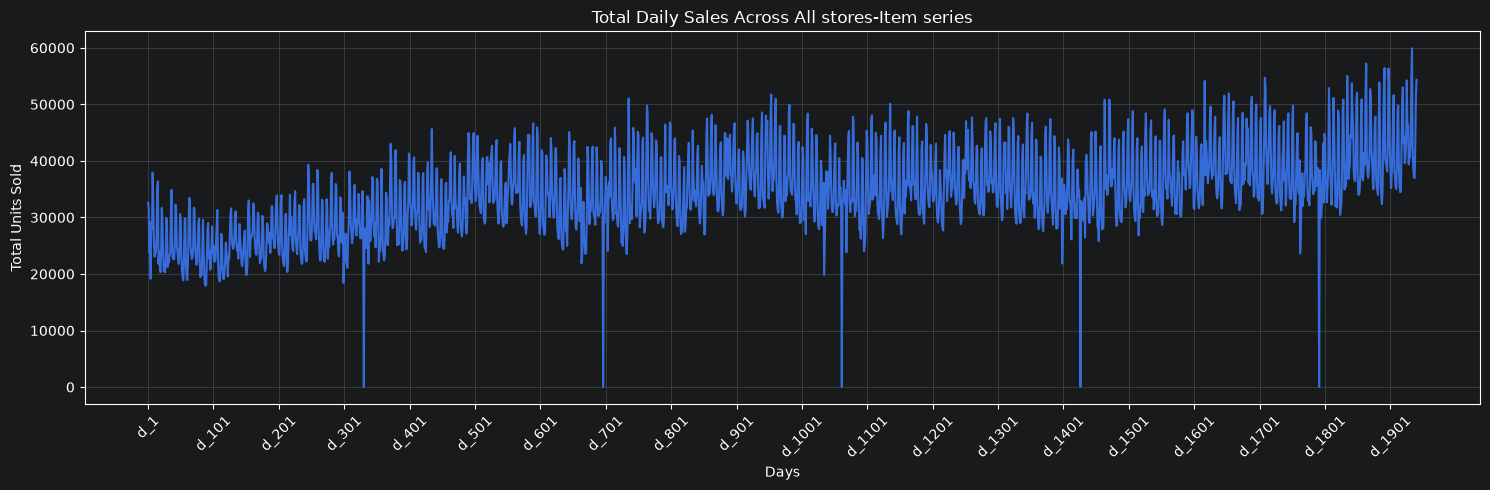

In [7]:
daily_sales = sales.iloc[:, 6:].sum(axis=0)

plt.figure(figsize=(15, 5))
plt.plot(daily_sales.values)

ticks = np.arange(0, len(daily_sales), 100)
labels=[daily_sales.index[i] for i in ticks]

plt.xticks(ticks, labels, rotation=45)
plt.title("Total Daily Sales Across All stores-Item series")
plt.xlabel("Days")
plt.ylabel("Total Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

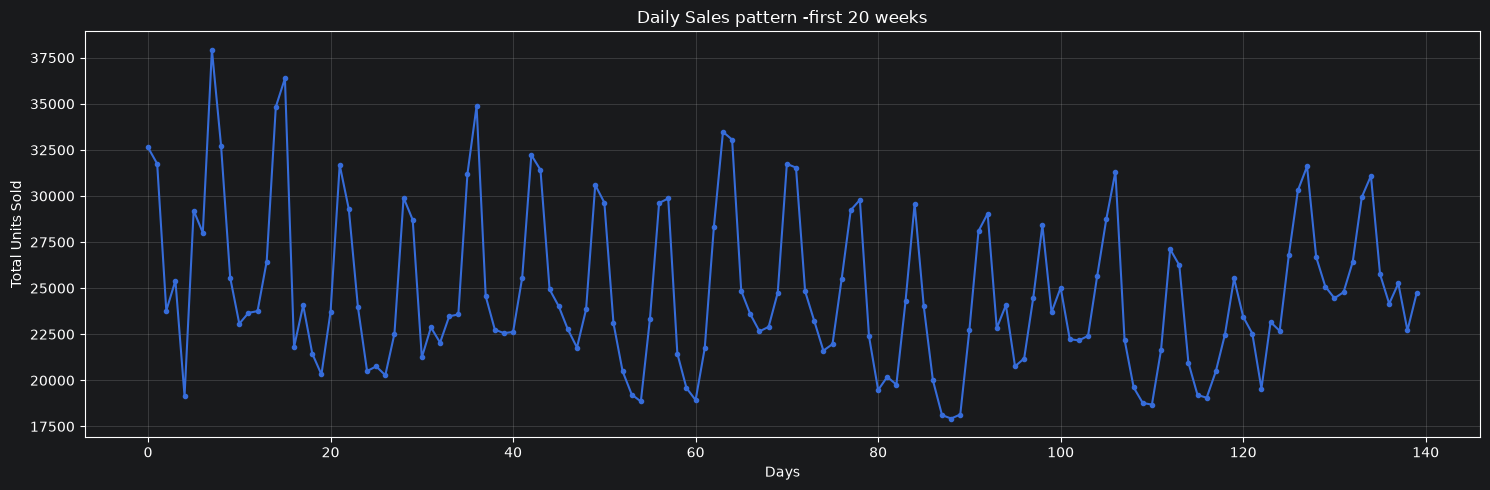

In [8]:
first_140=daily_sales.iloc[:140]

plt.figure(figsize=(15, 5))
plt.plot(first_140.values,marker="o",markersize=3)
plt.title("Daily Sales pattern -first 20 weeks")
plt.xlabel("Days")
plt.ylabel("Total Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
#  weekday sales by weekday position
weekday_pattern=first_140.groupby(np.arange(len(first_140))%7).mean()
print("\nAverage daily sales by weekday (0=Sunday, 6=Saturday):")
print(weekday_pattern)


Average daily sales by weekday (0=Sunday, 6=Saturday):
0    30640.45
1    29975.10
2    23424.45
3    22054.20
4    21327.35
5    21887.30
6    24739.45
dtype: float64


In [10]:
# understand caleder data

print("Calender columns:")
print(calendar.columns.tolist())

print("\nCalendar data types:")
print(calendar.dtypes)

print("\nCalendar missing values:")
print(calendar.isnull().sum().sort_values(ascending=False))

print("\nCalendar unique values:")
print("Dates:", calendar['date'].nunique())
print("Weekdays:", calendar['weekday'].nunique())
print("Years:", calendar['year'].nunique())


Calender columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

Calendar data types:
date              str
wm_yr_wk        int64
weekday           str
wday            int64
month           int64
year            int64
d                 str
event_name_1      str
event_type_1      str
event_name_2      str
event_type_2      str
snap_CA         int64
snap_TX         int64
snap_WI         int64
dtype: object

Calendar missing values:
event_type_2    1964
event_name_2    1964
event_name_1    1807
event_type_1    1807
date               0
wm_yr_wk           0
year               0
month              0
wday               0
weekday            0
d                  0
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

Calendar unique values:
Dates: 1969
Weekdays: 7
Years: 6


In [11]:
print(calendar[["d", "date", "weekday", "month", "year"]].head(10))

print("\nFirst day:", calendar["date"].min())
print("\nLast day:", calendar["date"].max())

print("\nUnique day IDs:", calendar["d"].nunique())

      d        date    weekday  month  year
0   d_1  2011-01-29   Saturday      1  2011
1   d_2  2011-01-30     Sunday      1  2011
2   d_3  2011-01-31     Monday      1  2011
3   d_4  2011-02-01    Tuesday      2  2011
4   d_5  2011-02-02  Wednesday      2  2011
5   d_6  2011-02-03   Thursday      2  2011
6   d_7  2011-02-04     Friday      2  2011
7   d_8  2011-02-05   Saturday      2  2011
8   d_9  2011-02-06     Sunday      2  2011
9  d_10  2011-02-07     Monday      2  2011

First day: 2011-01-29

Last day: 2016-06-19

Unique day IDs: 1969


In [12]:
#  understand sales prices dataset

print("Columns:")
print(sell_prices.columns.tolist())

print("\nData types:")
print(sell_prices.dtypes)

print("\nMissing values:")
print(sell_prices.isnull().sum())

print("\nUnique values:")
print("Stores:", sell_prices['store_id'].nunique())
print("Items:", sell_prices['item_id'].nunique())
print("Weeks:", sell_prices['wm_yr_wk'].nunique())

print("\nPrice statistics:")
print(sell_prices['sell_price'].describe())

Columns:
['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

Data types:
store_id          str
item_id           str
wm_yr_wk        int64
sell_price    float64
dtype: object

Missing values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

Unique values:
Stores: 10
Items: 3049
Weeks: 282

Price statistics:
count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64


In [13]:
example=sell_prices[
    (sell_prices['store_id'] == 'CA_1') &
    (sell_prices['item_id'] == 'HOBBIES_1_001')
]

display(example.head(10))

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26
5,CA_1,HOBBIES_1_001,11330,8.26
6,CA_1,HOBBIES_1_001,11331,8.26
7,CA_1,HOBBIES_1_001,11332,8.26
8,CA_1,HOBBIES_1_001,11333,8.26
9,CA_1,HOBBIES_1_001,11334,8.26


In [14]:
prices_changes=(
    sell_prices
    .sort_values(by=['store_id', 'item_id', 'wm_yr_wk'])
    .groupby(['store_id', 'item_id'])['sell_price']
    .nunique()
)

print("Total store-item combinations:",len(prices_changes))
print("Price never changes:",(prices_changes==1).sum())
print("Price changes at least once:",(prices_changes>1).sum())

print("\nPercentage:")
print(f"Price never changes:{(prices_changes==1).sum()/len(prices_changes)*100:.2f}%")
print(f"Price changes :{(prices_changes>1).mean()*100:.2f}%")

Total store-item combinations: 30490
Price never changes: 8247
Price changes at least once: 22243

Percentage:
Price never changes:27.05%
Price changes :72.95%


Data preprocessing


In [15]:
# covert sales data from wide to long format

id_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']

long_sales = sales.melt(
id_vars=id_cols, var_name='d', value_name='sales'
)
print("Shape:", long_sales.shape)
display(long_sales.head(10))

Shape: (59181090, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
5,HOBBIES_1_006_CA_1_evaluation,HOBBIES_1_006,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
6,HOBBIES_1_007_CA_1_evaluation,HOBBIES_1_007,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
7,HOBBIES_1_008_CA_1_evaluation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,CA,d_1,12
8,HOBBIES_1_009_CA_1_evaluation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,CA,d_1,2
9,HOBBIES_1_010_CA_1_evaluation,HOBBIES_1_010,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [3]:
#sales+calender

long_sales=long_sales.merge(calendar, on='d', how='left')
print("Shape after merging with calendar:", long_sales.shape)
display(long_sales.head(10))

NameError: name 'long_sales' is not defined

In [2]:
#sales+price

long_sales=long_sales.merge(
    sell_prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left'
)
print("Shape after merging with sell_prices:", long_sales.shape)
display(long_sales.head())

NameError: name 'long_sales' is not defined

In [1]:
print("\nMissing values after merging:")
print(long_sales["sell_prices"].isna().sum())

print("\nPrice coverage:")
print(long_sales["sell_price"].notna().mean()*100)


Missing values after merging:


NameError: name 'long_sales' is not defined

In [3]:
missing_prices = long_sales[long_sales["sell_price"].isna()]
print("Missing price rows:",len(missing_prices))
print("\nMissing price by stores:")
display(missing_prices["store_id"].value_counts())
print("\nMissing price by items:")
display(missing_prices["item_id"].value_counts().head(10))

NameError: name 'long_sales' is not defined

In [4]:
missing_check=(
    long_sales[long_sales["sell_price"].isna()]
    .groupby(["store_id","item_id"])["date"]
    .agg(["min","max","count"])
    .sort_values("count", ascending=False)
)

display(missing_check.head(10))

NameError: name 'long_sales' is not defined

In [ ]:
missing_prices = long_sales[long_sales["sell_price"].isna()]

print("Missing-prices rows:",missing_prices.sum())

print("Zero sales among missing prices rows:")
print((long_sales.loc[missing_prices,"sales"]==0).mean()*100)

print("\nNon-zero sales among missing-price rows:")
print((long_sales.loc[missing_prices,"sales"]>0).mean()*100)


In [ ]:
print("SNAP columns:")
print([col for col in  calendar.columns if col.startswith("snap")])

print("\nSNAP values:")
for col in ["snap_CA","snap_TX","snap_WI"]:
    print(f"\n{col}:")
    print(calendar[col].value_counts())

In [ ]:
#o snap benefit is not available ,1 snap benefit available 

print("Missing d:",long_sales["d"].isna().sum())
print("Duplicate store-item-day rows:",
      long_sales.duplicated(subset=["store_id","item_id","d"]).sum())
print("Total rows:",len(long_sales))

In [ ]:
# final missing value check after both merge
important_cols=[
    "item_id",
    "store_id",
    "state_id",
    "d",
    "date",
    "sales",
    "wm_yr_wk",
    "sell_price"
]
missing_summary=long_sales[important_cols].isnull().sum()

display(missing_summary)

Feature Enginering

In [ ]:
print(long_sales["date"])

In [ ]:
#convert date colums to datetime

long_sales["date"]=pd.to_datetime(long_sales["date"])

#check
print(long_sales["date"].dtype)
display(long_sales[["d","date"]].head())

In [ ]:
# previos days sales for each store -item series

long_sales["lag_1"]=(
    long_sales
    .groupby(["store_id","item_id"])["sales"]
    .shift(1)
)

display(
    long_sales[
        ["store_id","item_id","date","sales","lag_1"]
    ].head(15)
)

In [ ]:
#create lag featers

group_cols=["store_id","item_id"]

for lag in[7,14,28,56]:
    long_sales[f"lag_{lag}"]=(
        long_sales
        .groupby(group_cols)["sales"]
        .shift(lag)
    )

    display(
        long_sales[
            ["store_id","item_id","date","sales","lag_1","lag_7","lag_14","lag_28","lag_56"]
        ].head(70)
    )

all are nan beacuse which oneraw we see that is first day(2011-01-29) ha,first day to prious day is not available

In [ ]:
#Rolling featers based on previous sales

group_cols=["store_id","item_id"]

long_sales["roll_mean_7"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(7).mean())
)

long_sales["roll_std_7"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(7).std())
)
long_sales["roll_mean_28"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(28).mean())
)

long_sales["roll_std_28"]=(
    long_sales
    .groupby(group_cols)["sales"]
    .transform(lambda x:x.shift(1).rolling(28).std())
)

display(
    long_sales[
        ["store_id","item_id","date","sales",
         "roll_mean_7","roll_std_7",
         "roll_mean_28","roll_std_28"]
    ].head(40)
)

In [ ]:
example=long_sales[
    (long_sales["store_id"]=="CA_1") &
    (long_sales["item_id"]=="HOBBIES_1_001")

].iloc[25:35]

display(
    example[
        ["date","sales","roll_mean_7","roll_std_7","roll_mean_28","roll_std_28"]
    ]
)

In [ ]:
#calender based features
long_sales["day_of_week"]=long_sales["date"].dt.dayofweek
long_sales["day_of_month"]=long_sales["date"].dt.day
long_sales["week_of_year"]=long_sales["date"].dt.isocalendar().week.astype("int16")
long_sales["month_num"]=long_sales["date"].dt.month
long_sales["year_num"]=long_sales["date"].dt.year

display(
    long_sales[
        ["date","days_of_week","day_of_month","week_of_year","month_num","year_num"]
    ].head(10)
)





In [ ]:
#check event information

event_cols=["event_name_1","event_type_1","event_name_2","event_type_2"]

for col in event_cols:
    print(f"\n{col}:")
    print(calendar[col].value_counts(dropna=False).head(10))

In [ ]:
#event indicater

long_sales["is_event"]=(
    long_sales["event_name_1"].notna() |
    long_sales["event_name_2"].notna()
).astype("int8")

print(long_sales["is_event"].value_counts())

display(
    long_sales[
        ["date","event_name_1","event_name_2","is_event"]
    ].head(20)
)

#0 it has no any event 1 means event ha

In [ ]:
long_sales["snap"].np.select(
    [
        long_sales["state_id"]=="CA",
        long_sales["state_id"]=="TX",
        long_sales["state_id"]=="WI"
    ],
    [
        long_sales["snap_CA"],
        long_sales["snap_TX"],
        long_sales["snap_WI"],

    ],
    default=0
)

print(long_sales["snap"].value_counts())

display(
    long_sales[
        ["state_id","date","snap_CA","snap_TX","snap_WI","snap"]
    ].head(10)
)

In [ ]:
# sort data properly

long_sales=long_sales.sort_values(
    ["store_id","item_id","date"]
)

#prious avaible price
long_sales["prev_price"]=(
    long_sales
    .groupby(["store_id","item_id"])["sell_price"]
    .shift(1)
)

#price chage amount
long_sales["price_change"]=(
    long_sales["sell_price"]-long_sales["prev_price"]
)

#price change percentage

long_sales["price_change_pct"]=(
    long_sales["price_change"]/long_sales["prev_price"]
)*100

display(
    long_sales[
        ["store_id","item_id","date","sell_price","prev_price","price_change","price_change_pct"]
    ].head(20)
)

In [1]:
long_sales["is_price_change"]=(
    long_sales["price_change"]!=0
).astype("int8")

display(
    long_sales[
        ["date","sell_price","prev_price","price_change","price_change_pct","is_price_change"]
    ].head(20)
)

NameError: name 'long_sales' is not defined

In [ ]:
# demand /intermittency featers
group_cols=["store_id","item_id"]

# Previous 7 days ka zero-sales ratio
long_sales["zero_ratio_7"] = (
    long_sales
    .groupby(group_cols)["sales"]
    .transform(
        lambda x: x.shift(1).eq(0).rolling(7).mean()
    )
)

# Previous 28 days ka zero-sales ratio
long_sales["zero_ratio_28"] = (
    long_sales
    .groupby(group_cols)["sales"]
    .transform(
        lambda x: x.shift(1).eq(0).rolling(28).mean()
    )
)

# Previous sale kab hui thi?
last_sale_date = (
    long_sales["date"]
    .where(long_sales["sales"] > 0)
    .groupby(
        [long_sales["store_id"], long_sales["item_id"]]
    )
    .ffill()
)

# Current day's sale ko use na karne ke liye shift
last_sale_date = (
    last_sale_date
    .groupby(
        [long_sales["store_id"], long_sales["item_id"]]
    )
    .shift(1)
)

long_sales["days_since_last_sale"] = (
    long_sales["date"] - last_sale_date
).dt.days

display(
    long_sales[
        [
            "store_id", "item_id", "date", "sales",
            "zero_ratio_7", "zero_ratio_28",
            "days_since_last_sale"
        ]
    ].head(40)
)

In [ ]:
# Calculate demand statistics for each store-item series

demand_stats = (
    long_sales
    .groupby(["store_id", "item_id"])
    .agg(
        total_demand=("sales", "sum"),
        total_days=("sales", "count"),
        non_zero_days=("sales", lambda x: (x > 0).sum()),
        mean_sales=("sales", "mean"),
        std_sales=("sales", "std")
    )
    .reset_index()
)

# Average Demand Interval (ADI)
demand_stats["ADI"] = (
    demand_stats["total_days"] /
    demand_stats["non_zero_days"].replace(0, np.nan)
)

# Coefficient of variation squared (CV²)
demand_stats["CV2"] = (
    demand_stats["std_sales"] /
    demand_stats["mean_sales"].replace(0, np.nan)
) ** 2

display(demand_stats.head(10))

In [ ]:
# Demand classification thresholds
ADI_THRESHOLD = 1.32
CV2_THRESHOLD = 0.49

def classify_demand(row):
    if row["non_zero_days"] == 0:
        return "No Demand"

    if row["ADI"] < ADI_THRESHOLD:
        if row["CV2"] < CV2_THRESHOLD:
            return "Smooth"
        else:
            return "Erratic"
    else:
        if row["CV2"] < CV2_THRESHOLD:
            return "Intermittent"
        else:
            return "Lumpy"


demand_stats["demand_class"] = demand_stats.apply(
    classify_demand,
    axis=1
)

print(demand_stats["demand_class"].value_counts())

display(
    demand_stats[
        ["store_id", "item_id", "ADI", "CV2", "demand_class"]
    ].head(20)
)

In [ ]:
import gc

gc.collect()

print(long_sales.shape)

In [ ]:
# find days where total sales across all series were zero

closed_days=daily_sales[daily_sales==0].index
print("Zero-sales days:")
print(list(closed_days))
print("Count:",len(closed_days))

In [ ]:
#store closer indicaters
long_sales["is_store_closed"]=long_sales["d"].isin(closed_days).astype(int8)

print(long_sales["is_store_closed"].value_counts())

prious assuptions are not correct graph have yuge drop that are not exactlly 0 seles but low sales

In [ ]:
# Typical price of each store-item
median_price = (
    long_sales
    .groupby(["store_id", "item_id"])["sell_price"]
    .transform("median")
)

# Price relative to its typical price
long_sales["price_norm"] = (
    long_sales["sell_price"] / median_price
)

display(
    long_sales[
        ["store_id", "item_id", "date",
         "sell_price", "price_norm"]
    ].head(20)
)

In [ ]:
#final featers inventory

print("Total columns:",len(long_sales.columns))
print("\nAll columns:")

for i ,col in enumerate(long_sales.columns,1):
    print(i,"->",col)

In [ ]:
print("\nData types:")
print(long_sales.dtypes)

In [ ]:
# Final feature groups

TARGET = ["sales"]

ID_COLS = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

DATE_COLS = [
    "d",
    "date"
]

CALENDAR_FEATURES = [
    "wm_yr_wk",
    "wday",
    "month",
    "year",
    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month_num",
    "year_num"
]

PRICE_FEATURES = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "is_price_change",
    "price_norm"
]

LAG_FEATURES = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "lag_56"
]

ROLLING_FEATURES = [
    "roll_mean_7",
    "roll_std_7",
    "roll_mean_28",
    "roll_std_28"
]

DEMAND_FEATURES = [
    "zero_ratio_7",
    "zero_ratio_28",
    "days_since_last_sale"
]

EVENT_FEATURES = [
    "is_event"
]

SNAP_FEATURES = [
    "snap"
]

FEATURES = (
    CALENDAR_FEATURES
    + PRICE_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + DEMAND_FEATURES
    + EVENT_FEATURES
    + SNAP_FEATURES
)

print("Total model features:", len(FEATURES))
print(FEATURES)

In [ ]:
# check missing values in model featers

missing_features=long_sales[FEATURES].isna().sum()

print("Missing values in model features:")
print(missing_features[missing_features>0])

- sell_price ke NaN → jahan price missing hai, wahan sales bhi 0 thi.
- Lag features → starting days mein previous days available nahi hain.
- Rolling features → starting 7/28 days mein enough history nahi hai.
- days_since_last_sale → jab pehli sale se pehle history nahi hai.

Training ke liye hume enough historical information wali rows chahiye.
Pehle calculate karte hain ki agar hum first 56 days hata dein,
to kitni rows bachti hain.

In [ ]:
# Check how many rows have complete lag/rolling history

history_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "lag_56",
    "roll_mean_7",
    "roll_std_7",
    "roll_mean_28",
    "roll_std_28"
]

complete_history = long_sales[history_cols].notna().all(axis=1)

print("Rows with complete history:", complete_history.sum())
print("Rows without complete history:", (~complete_history).sum())
print("Total rows:", len(long_sales))

so sirf 2.9% rows history incompltete Abhi sirf history based NAN drop kar sakte hai because model ke lye ye features available nahi ha 

In [ ]:
#count rows with incomplte history without modifying long_sales

print("Rows with complete history:",complete_history.sum())
print("Rows without complete history:", (~complete_history).sum())
print("Total rows:", len(long_sales))

In [ ]:
# Restore original "no previous sale" information

long_sales.loc[
    long_sales["no_previous_sale"] == 1,
    "days_since_last_sale"
] = -1

print(
    long_sales["days_since_last_sale"]
    .value_counts()
    .sort_index()
    .head(15)
)

these fetaers are useless hai because complte zero sales day nahi ha 

In [ ]:
# Remove useless store-closure feature

long_sales.drop(
    columns=["is_store_closed"],
    inplace=True,
    errors="ignore"
)

print("is_store_closed" in long_sales.columns)

In [ ]:
# Final model features update
# no_previous_sale is also useful, so add it

DEMAND_FEATURES = [
    "zero_ratio_7",
    "zero_ratio_28",
    "days_since_last_sale",
    "no_previous_sale"
]

FEATURES = (
    CALENDAR_FEATURES
    + PRICE_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + DEMAND_FEATURES
    + EVENT_FEATURES
    + SNAP_FEATURES
)

print("Total model features:", len(FEATURES))
print(FEATURES)

In [ ]:
#final missing value check

missing_final=long_sales[FEATURES].isna().sum()
print("Features with missing values:")
print(missing_final[missing_final>0])

In [ ]:
# Price availability flag

long_sales["price_available"] = (
    long_sales["sell_price"].notna()
).astype("int8")

print(long_sales["price_available"].value_counts())

In [ ]:
# Fill missing price-related values

price_fill_cols = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "price_norm"
]

long_sales[price_fill_cols] = (
    long_sales[price_fill_cols].fillna(0)
)

In [ ]:
PRICE_FEATURES = [
    "sell_price",
    "price_change",
    "price_change_pct",
    "is_price_change",
    "price_norm",
    "price_available"
]

FEATURES = (
    CALENDAR_FEATURES
    + PRICE_FEATURES
    + LAG_FEATURES
    + ROLLING_FEATURES
    + DEMAND_FEATURES
    + EVENT_FEATURES
    + SNAP_FEATURES
)

print("Total model features:", len(FEATURES))

In [ ]:
missing_final=long_sales[FEATURES].isna().sum()
print("Remaining missing values:")
print(missing_final[missing_final>0])

ye expected hain because itinal days mein past history available nahi thi

                             Time-based train/vaildation split

In [ ]:
# Time-based train/validation split

HOLDOUT_DAYS = 28
FINAL_DAY = 1941
CUTOFF_DAY = FINAL_DAY - HOLDOUT_DAYS

print("CUTOFF_DAY:", CUTOFF_DAY)
print("FINAL_DAY:", FINAL_DAY)

In [ ]:
long_sales["is_holdout"] = (
    long_sales["d"].str.replace("d_", "").astype("int16") > CUTOFF_DAY
).astype("int8")

print(long_sales["is_holdout"].value_counts())

0- trainning period last 28 days=validate/holdout

In [ ]:
print("Training days:")
print(
    long_sales.loc[long_sales["is_holdout"] == 0, "d"]
    .drop_duplicates()
    .tail()
    .tolist()
)

print("\nHoldout days:")
print(
    long_sales.loc[long_sales["is_holdout"] == 1, "d"]
    .drop_duplicates()
    .head()
    .tolist()
)

print(
    long_sales.loc[long_sales["is_holdout"] == 1, "d"]
    .drop_duplicates()
    .tail()
    .tolist()
)

In [ ]:
print("Training rows:",
      (long_sales["is_holdout"] == 0).sum())

print("Holdout rows:",
      (long_sales["is_holdout"] == 1).sum())

In [ ]:
# Check lag features inside holdout

display(
    long_sales.loc[
        long_sales["is_holdout"] == 1,
        [
            "store_id",
            "item_id",
            "d",
            "sales",
            "lag_1",
            "lag_7",
            "lag_28"
        ]
    ].head(20)
)

In [ ]:
# Validation cutoff
VALIDATION_ORIGIN = 1913

print("Validation origin:", VALIDATION_ORIGIN)
print("Forecast horizon:", 28)
print("Forecast days: d_1914 -> d_1941")

In [ ]:
# Check history at validation origin

origin_check = long_sales[
    long_sales["d"] == "d_1913"
]

print("Rows at validation origin:", len(origin_check))

print("\nMissing lag/rolling features:")
print(
    origin_check[
        LAG_FEATURES + ROLLING_FEATURES
    ].isna().sum()
)

In [ ]:
#check first validation day
val_day=long_sales[
    long_sales["d"]=="d_1914"
]

display(
    val_day[
                  "store_id",
                    "item_id",
                    "d",
                    "sales",
                    "lag_1",
                    "lag_7",
                    "lag_14",
                    "lag_28"
        
    ]head(10)
)

In [ ]:
#Recurisvive 28 daus forcasting

VALIDATION_ORIGIN=1913
H=28

forecast_days=[
    f"d_{VALIDATION_ORIGIN+i}"
    for i in range(1,H+1)
]

print("Forecast_days:")
print(forecast_days)

In [ ]:
def recursive_forecast(model, X_val_base, history):

    predictions = {}

    for day in forecast_days:

        # Features for current day
        X_day = X_val_base[day]

        # Predict current day
        pred = model.predict(X_day)

        # Save prediction
        predictions[day] = pred

        # IMPORTANT:
        # Current prediction will be used as history
        # for the next forecast day.
        history = update_history(
            history,
            pred
        )

    return predictions

In [ ]:
# Rows with complete lag/rolling history

train_history_mask = (
    long_sales[LAG_FEATURES + ROLLING_FEATURES]
    .notna()
    .all(axis=1)
)

# Training period only
train_mask = (
    (long_sales["is_holdout"] == 0)
    & train_history_mask
)

print(
    "Training rows with complete history:",
    train_mask.sum()
)

Training ke time sirf wahi rows use karo jinke saare lag + rolling features available hain.

Har row ko check karo ki uske saare lag + rolling features available hain ya nahi.

In [ ]:
TARGET = "sales"

TRAIN_COLUMNS = FEATURES + [TARGET]

print("Training columns:", len(TRAIN_COLUMNS))
print(TRAIN_COLUMNS)

In [ ]:
import os
import json

# Folder for modeling artifacts
MODEL_DATA_DIR = "data/model_ready"
os.makedirs(MODEL_DATA_DIR, exist_ok=True)

# Columns needed by model.ipynb
MODEL_ID_COLS = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
    "d",
    "date"
]

MODEL_META_COLS = [
    "sales",
    "is_holdout"
]

MODEL_SAVE_COLS = list(dict.fromkeys(
    MODEL_ID_COLS
    + FEATURES
    + MODEL_META_COLS
))

missing_cols = [
    col for col in MODEL_SAVE_COLS
    if col not in long_sales.columns
]

print("Missing columns:", missing_cols)
print("Columns to save:", len(MODEL_SAVE_COLS))

print(MODEL_SAVE_COLS)

31 = model training columns, 40 = total columns being saved in the Parquet file.

ADI, CV2, and demand_class are not included in the 40 columns because they are stored separately in demand_stats.

| Category                |  Count | Purpose                                                      |
| ----------------------- | -----: | ------------------------------------------------------------ |
| Model Features          |     30 | Model actually uses these features for prediction            |
| Target                  |      1 | `sales` — what the model predicts                            |
| ID Columns              |      — | `store_id`, `item_id`, `dept_id`, `cat_id`, `state_id`, `id` |
| Date/Time Columns       |      — | `d`, `date`, `wm_yr_wk`                                      |
| Holdout Indicator       |      1 | `is_holdout` — identifies training vs holdout rows           |
| **Total Saved Columns** | 40 | **Columns saved in the Parquet file for modeling**           |

In [ ]:
feature_config = {
    "TARGET": "sales",
    "FEATURES": FEATURES,
    "CALENDAR_FEATURES": CALENDAR_FEATURES,
    "PRICE_FEATURES": PRICE_FEATURES,
    "LAG_FEATURES": LAG_FEATURES,
    "ROLLING_FEATURES": ROLLING_FEATURES,
    "DEMAND_FEATURES": DEMAND_FEATURES,
    "EVENT_FEATURES": EVENT_FEATURES,
    "SNAP_FEATURES": SNAP_FEATURES,
    "ID_COLS": MODEL_ID_COLS,
    "META_COLS": MODEL_META_COLS,
    "HOLDOUT_DAYS": 28,
    "FINAL_DAY": 1941,
    "CUTOFF_DAY": 1913
}

with open(
    os.path.join(MODEL_DATA_DIR, "feature_config.json"),
    "w"
) as f:
    json.dump(feature_config, f, indent=2)

print("Feature configuration saved.")

In [ ]:
import os
import pyarrow as pa
import pyarrow.parquet as pq

MODEL_DATA_DIR = "data/model_ready"
os.makedirs(MODEL_DATA_DIR, exist_ok=True)

DATA_PATH = os.path.join(
    MODEL_DATA_DIR,
    "m5_model_features.parquet"
)

writer = None
chunk_size = 500_000

try:
    for start in range(0, len(long_sales), chunk_size):
        end = min(start + chunk_size, len(long_sales))

        chunk = long_sales.iloc[start:end][MODEL_SAVE_COLS]

        table = pa.Table.from_pandas(
            chunk,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                DATA_PATH,
                table.schema,
                compression="snappy"
            )

        writer.write_table(table)

        print(f"Saved: {end:,} / {len(long_sales):,}")

finally:
    if writer is not None:
        writer.close()

print("Done:", DATA_PATH)